# Basic M3 Data Processing Tutorial

_Opening, closing, and doing other basic things with M3 FITS images._

### Python Libraries

In [1]:
import numpy as np                # for scientific computing, good for working with large arrays  
import pandas as pd               # for data analysis, has easy to work with data frames 
import matplotlib.pyplot as plt   # for plotting 
from astropy.io import fits       # for reading / writing / manipulating FITS files 

### FITS files 

M3 files are stored in the USGS PDS as FITS files. FITS stands for "Flexible Image Transport System." FITS is widely used in astronomy for scientific data and can store multidimensional arrays or tables. 

FITS files are broken up into Header/Data Units called HDUs. The Header component contains metadata, while the optional Data unit contains an array or table. A FITS file may have multiple HDUs or just one. The first HDU in a FITS file is called the primary HDU. 

#### Opening FITS files with GUIs 

This notebook focuses on using Python with M3 data. However, it is often preferable to open FITS images with GUIs. Some options for free software that can open FITS images:
- SAOImageDS9 / DS9 (https://sites.google.com/cfa.harvard.edu/saoimageds9) 
- ImageJ / Fiji (Fiji is ImageJ with more bells and whistles)

NASA has a more extensive list of FITS tools / image viewers: https://fits.gsfc.nasa.gov/fits_viewer.html

#### Opening FITS files with Python  
We can open a fits file using the astropy library, which we loaded above as "fits". 

We could alternatively use the Planetary Data Reader (PDR), https://github.com/millionconcepts/pdr, which wraps the astropy fits library, and supports a wide variety of planetary data formats. 

In [2]:
# we are looking at observation m3g20090420t191718 simply because it has a small file size for L1B / L2 
path_to_l0 = "./tutorial_data/m3g20090420t191718_l0.fits"  # a level 0 ("l0") observation where the values are in DN  

with fits.open(path_to_l0) as hdul: 
    l0_header = hdul[0].header         # 0 is used to access the first (primary) HDU of the file. 
    l0_image = hdul[0].data

Here the header of the primary (and only HDU) for the L0 data contains basic information like the data unit's array size and data type.

In [3]:
l0_header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                   16 / array data type                                
NAXIS   =                    3 / number of array dimensions                     
NAXIS1  =                  320                                                  
NAXIS2  =                  844                                                  
NAXIS3  =                   86                                                  
EXTEND  =                    T                                                  

The data unit of the primary HDU of the L0 file contains all bands of the M3 observation in DN. Astropy opens the image as a NumPy ndarray object. We can get the shape of the image by checking the '.shape' attribute. 

In [4]:
l0_image.shape

(86, 844, 320)

Note that the axes order above is reversed from that in the FITS header. In the image ndarray, the axes are as follows: 
- __Axis 0__: 86, the number of __bands__ in global mode L0
- __Axis 1__: 844, the number of __lines__ (down-track) in global mode L0. Variable by observation.
- __Axis 2__: 320, the number of __samples__ (cross-track) in global mode L0

Target mode has more samples (640) and bands (260) than global mode. 

Lower bands correspond to shorter wavelengths and higher bands are longer wavelengths.

#### Writing FITS files 

After you manipulate or subset an M3 observation in some way you can save it as a new FITS file. 

In [5]:
# very simple way to write a FITS file (if you  uncommented the line below)

# fits.writeto('l0_band_30.fits', l0_image[30], overwrite=True)

It is also possible to write multiple HDUs, extra information in the header, etc. 

### Manipulating and Viewing Observation Images

Once your image is open, you may want to manipulate the axes order or do other basic math with the ndarray. 

You can index the ndarray to acess specific bands or lines. Here we load the L1B radiance fits file for the same observation as before, and then view only the 85th band (0-indexed) using matplotlib to view the image. 

In [6]:
path_to_l1b = "./tutorial_data/m3g20090420t191718_l1b_rdn.fits"

with fits.open(path_to_l1b) as hdul: 
    l1b_header = hdul[0].header         
    l1b_image = hdul[0].data

#### Viewing a single band 

For simply viewing sections of images for quality etc, it may be easier to open the FITS file with a GUI image viewer like ds9. With 
ds9, stretching and zooming / moving around the image is very easy. 

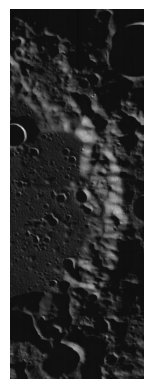

In [7]:
# viewing band 85 (0-indexed is 84) 
plt.imshow(l1b_image[84], cmap='grey')
plt.axis('off')
plt.show()

We can view a smaller section of band 85 by indexing the NumPy array.  

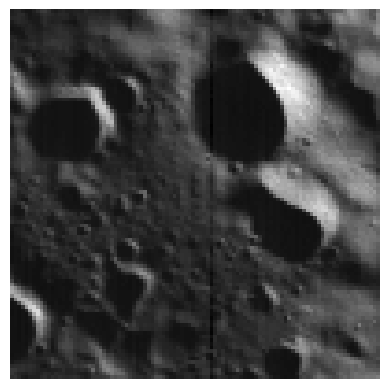

In [8]:
# viewing band 85 (0-indexed is 84) 
plt.imshow(l1b_image[84, 400:500, 100:200], cmap='grey') # [band, lines, samples] -> [band, start_line:end_line, start_sample:end_sample]
plt.axis('off')
plt.show()

We can also do band with the image ndarray and view the result as an image. 

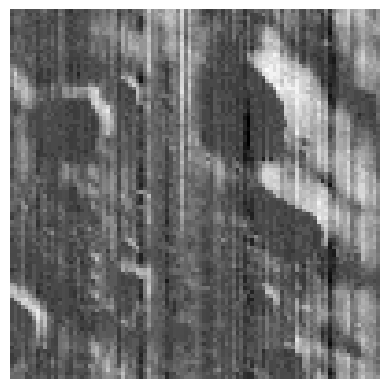

In [9]:
# difference of bands 80 and 79 (0-indexed) for the same area as above 
plt.imshow(l1b_image[79, 400:500, 100:200]-l1b_image[80, 400:500, 100:200], cmap='grey') 
plt.axis('off')
plt.show()

Some detector noise not removed by flat fielding and dark signal subtraction is clearly visible in the difference image above. 

#### Viewing an observation in "detector" view 

We can also view an observation in detector view, where the y-axis of the image is bands / channels and x-axis is samples / cross-track.

Here we look at a single line, aka frame, of a global mode observation. This is a kind of "instantaneous" view of what the detector was 
recording for all bands and samples. 

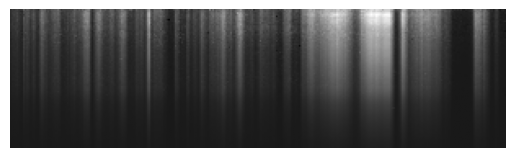

In [10]:
# viewing frame 500 of L1B 
plt.imshow(l1b_image[:, 500, :], cmap='grey') # using ':' in indexing selects all parts of that axis, so here we see all samples and bands
plt.axis('off')
plt.show()

The L1B image (above) is dominated by light from the surface of the moon after detector artifacts have been removed. 

The L0 image (below) still shows detector artifacts in addition to observational data.  

In the L0 image you can see these detector artifacts :
- Three vertical bright white lines = the readout columns of the detector panels.
- Two horizontal dark lines = filter seams of the detector.
- Bright, randomly distributed points = bad detector elements aka bad pixels. 

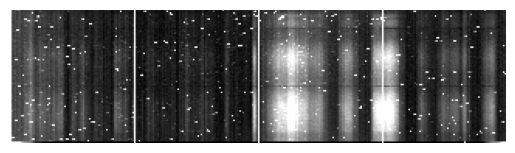

In [11]:
# viewing frame 500 of L0 
# using ':' in indexing selects all parts of that axis, so here we see all samples and bands
plt.imshow(l0_image[:, 500, :], cmap='grey', vmin=500, vmax=700) 
plt.axis('off')
plt.show()

As you can see, frame 500 for L0 and frame 500 for L1B do not match. 

The line, sample, and band number for L0 and L1B and L2 data do not always correspond because: 
1) Based on the geometry of the observation the lines and/or samples may have been reversed in L1B from L0.
2) Bands are dropped between L0 and L1B and L2. 

You can also write an observation in detector view to a FITS file by transposing the axes, like below. GUIs like ds9 also allow you to manipulate axes, but it usually slows the application down. 

In [12]:
# uncommenting the below line would write a detector-view version of the observation 

#fits.writeto('l0_detector_view.fits', l0_image.transpose(1,0,2), overwrite=True)

#### Viewing Spectra

We can view the spectra of a single pixel by indexing just that pixel across all bands for a single line and sample. Here we plot the radiance of a single pixel with matplotlib. 

Text(0.5, 0, 'band')

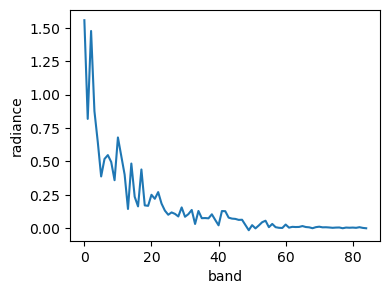

In [13]:
plt.figure(figsize=(4, 3))
plt.plot(l1b_image[:, 515, 260])
plt.ylabel("radiance")
plt.xlabel("band")

We can also take the average and median spectra for an area of the observation using NumPy. 

Text(0.5, 0, 'band')

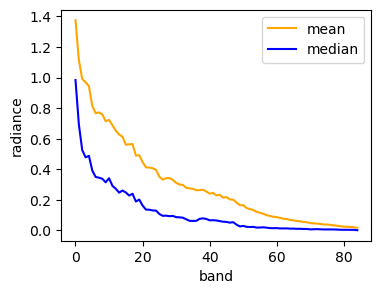

In [14]:
median_spectra = np.median(l1b_image[:, 500:520, 260:280], axis=(1,2)) # 20 x 20 box of cross-track and down-track pixels 
mean_spectra = np.mean(l1b_image[:, 500:520, 260:280], axis=(1,2))

plt.figure(figsize=(4, 3))
plt.plot(mean_spectra, color='orange', label='mean')
plt.plot(median_spectra, color='blue', label='median')
plt.legend()
plt.ylabel("radiance")
plt.xlabel("band")